<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 9: Multilayer Perceptron Implementation

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Construct and train a multi-layer neural network with non-linear activation functions on a 3-class spiral benchmark.


### Task 1: Multiclass Spiral Dataset Generation


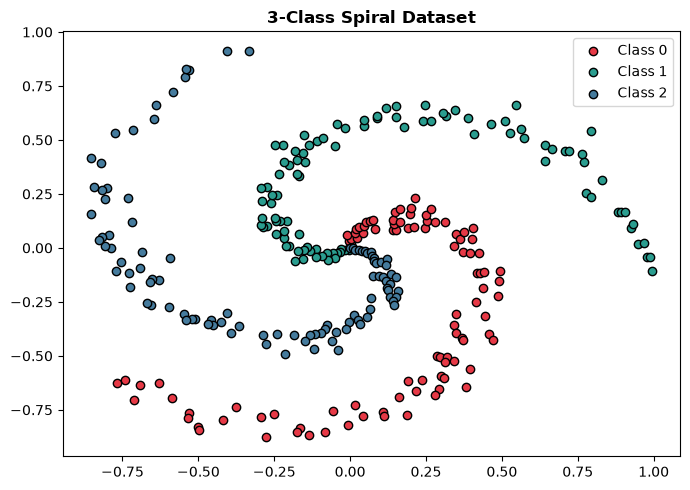

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(123)
n_points_per_class = 100
n_classes = 3

X_spiral = np.zeros((n_points_per_class * n_classes, 2))
y_spiral = np.zeros(n_points_per_class * n_classes, dtype='uint8')

for j in range(n_classes):
    ix = range(n_points_per_class * j, n_points_per_class * (j + 1))
    r = np.linspace(0.0, 1, n_points_per_class)
    t = np.linspace(j * 4, (j + 1) * 4, n_points_per_class) + np.random.randn(n_points_per_class) * 0.18
    X_spiral[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y_spiral[ix] = j

plt.figure(figsize=(7, 5))
palette = ['#e63946', '#2a9d8f', '#457b9d']
for k in range(n_classes):
    plt.scatter(X_spiral[y_spiral == k, 0], X_spiral[y_spiral == k, 1], color=palette[k], label=f'Class {k}', edgecolors='k')
plt.title("3-Class Spiral Dataset", fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


### Task 2: Define and Train PyTorch Multilayer Perceptron


In [2]:
# Convert to PyTorch tensors
X_tensor = torch.tensor(X_spiral, dtype=torch.float32)
y_tensor = torch.tensor(y_spiral, dtype=torch.long)

class DeepMLP(nn.Module):
    def __init__(self, in_features=2, hidden=32, num_classes=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, num_classes)
        )
    def forward(self, x):
        return self.net(x)

mlp_model = DeepMLP()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=0.03)

loss_history, acc_history = [], []
for epoch in range(350):
    optimizer.zero_grad()
    logits = mlp_model(X_tensor)
    loss = criterion(logits, y_tensor)
    loss.backward()
    optimizer.step()

    preds = torch.argmax(logits, dim=1)
    acc = (preds == y_tensor).float().mean().item() * 100
    loss_history.append(loss.item())
    acc_history.append(acc)

print(f"Trained MLP for 350 Epochs. Final Loss: {loss_history[-1]:.4f}, Accuracy: {acc_history[-1]:.2f}%")


Trained MLP for 350 Epochs. Final Loss: 0.0128, Accuracy: 99.33%


### Task 3: Plot Training Dynamics and Decision Surface


Execution Error: 'crest' is not a valid value for cmap. Did you mean one of: 'Greys', 'Greens', 'Accent'?
See `matplotlib.bivar_colormaps()` and `matplotlib.multivar_colormaps()` for bivariate and multivariate colormaps


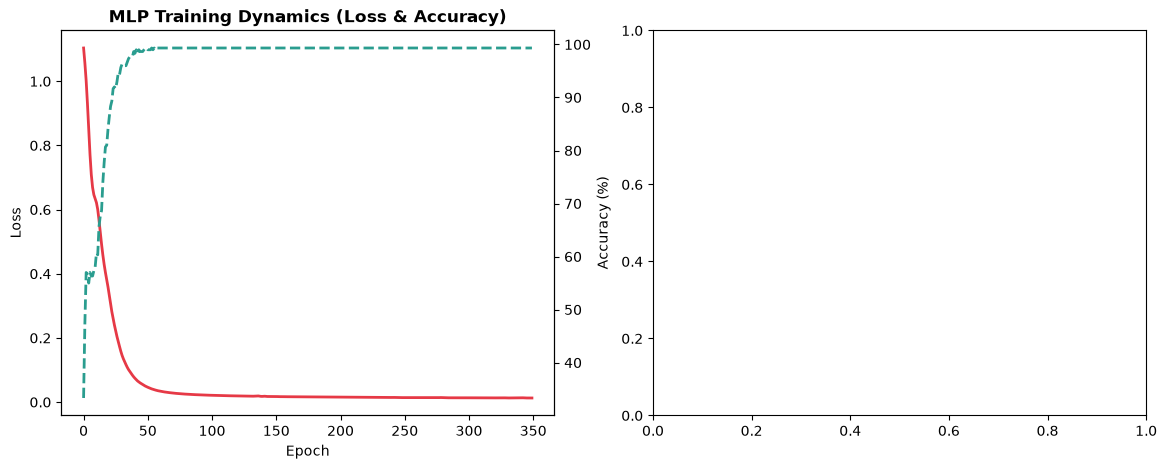

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(loss_history, color='#e63946', lw=2, label='Cross-Entropy Loss')
axes[0].set_ylabel("Loss")
axes[0].set_xlabel("Epoch")
ax0_twin = axes[0].twinx()
ax0_twin.plot(acc_history, color='#2a9d8f', lw=2, linestyle='--', label='Accuracy (%)')
ax0_twin.set_ylabel("Accuracy (%)")
axes[0].set_title("MLP Training Dynamics (Loss & Accuracy)", fontweight='bold')

# Decision surface
x_min, x_max = X_spiral[:, 0].min() - 0.2, X_spiral[:, 0].max() + 0.2
y_min, y_max = X_spiral[:, 1].min() - 0.2, X_spiral[:, 1].max() + 0.2
gx, gy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid_t = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)

with torch.no_grad():
    grid_preds = torch.argmax(mlp_model(grid_t), dim=1).numpy().reshape(gx.shape)

axes[1].contourf(gx, gy, grid_preds, levels=3, cmap='crest', alpha=0.5)
for k in range(3):
    axes[1].scatter(X_spiral[y_spiral == k, 0], X_spiral[y_spiral == k, 1], color=palette[k], edgecolors='k', label=f'Class {k}')
axes[1].set_title("Trained MLP Multi-Class Decision Manifold", fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()
